In [1]:
import sys
sys.path.append('..')

In [8]:
from src import SV_configs
from src import utils
import numpy as np
from types import SimpleNamespace
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib

In [3]:
args = {
    'data_out_dir' : 'data/',
    'results_out_dir' : 'results/',
    'name': 'unaligned',
    'num_seeds' : 1, 
    'override_load' : False,
    'trajectory_length' : 8,
    'num_samples' : 50,
    'num_epochs' : 500,
    'lr' : 5,
    'initialization_scale' : 1e-1,
    'input_size' : 3,
    'hidden_size' : 3,
    'output_size' : 3,
    'S_config': ['dirac_delta','dirac_delta','dirac_delta'],
    'delta' : [0.5,1.5,2.5], 
    'lambda_0' : [1,1,1], 
    'S_T' : [1,1,1],
    'S_TeqS_t' : False,
    'zero_balanced' : True,
    'frozen_hidden_layer' : False,
    'frozen_input_output' : False,
    'single_output_y' : True,
    'inout_mode_init' : [0.01,0.01,0.01],
    'in_mode_init' : [0.1,0.1,0.1],
    'out_mode_init': [0.1,0.1,0.1],
    'rec_mode_init': [0.01,0.01,0.01],
    'num_SV' : 3,
    'aligned_student_weights': True,
    'log_H': False,
    'log_y_hat': True,
    'compute_NTK': True,
    'nonlinear_RNN': False,
    'log_every_e_epoch': 1,
    'subsample_NTK': False
}
args = SimpleNamespace(**args)

In [4]:
args.S = SV_configs.create_SV_trajectories(args)

In [5]:
b_range = np.linspace(1.5,0.0,42)
u_range = np.linspace(0.0,1.5,42)
data_driven_term = np.zeros((args.num_SV, 42,42))
effective_regularization_term = np.zeros((args.num_SV, 42,42))

In [6]:
for alpha in range(args.num_SV):
    for i in range(len(b_range)):
        for j in range(len(u_range)):
            data_driven_term[alpha,i,j] = utils.compute_data_driven_term(args, args.S[:,alpha,alpha], u_range[j], b_range[i])
            effective_regularization_term[alpha,i,j] = utils.compute_effective_regularization_term(args, u_range[j], b_range[i])

/var/folders/88/p8znsc4j3wj6nq2cj7m_l4xr0000gn/T/ipykernel_20855/26990094.py:59: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = plt.cm.get_cmap('coolwarm')


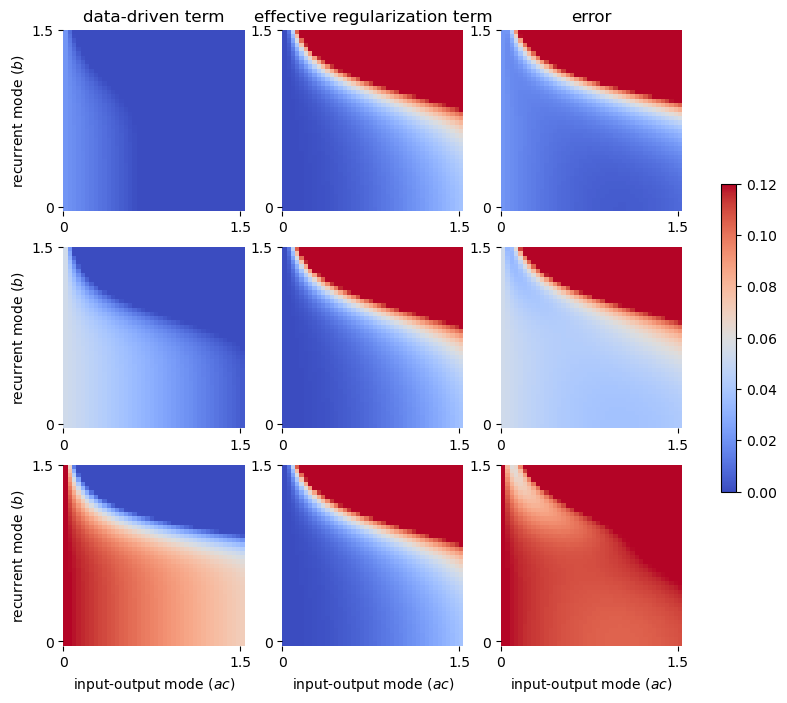

In [9]:
fig, axes = plt.subplots(args.num_SV, 3, figsize=(10, 8))
for alpha in range(args.num_SV):
    sns.heatmap(data_driven_term[alpha],
                ax=axes[alpha,0],
                xticklabels=False,  
                yticklabels=False,  
                cmap='coolwarm',  
                cbar=False,  
                vmin=0.,vmax=0.12,
                square=True)
    axes[alpha,0].set_ylabel(r'recurrent mode ($b$)')
    axes[alpha,0].set_xticks([0,41], [0,1.5])
    axes[alpha,0].set_yticks([0,41], [1.5,0])

    sns.heatmap(effective_regularization_term[alpha],
                ax=axes[alpha,1],
                xticklabels=False,  
                yticklabels=False,  
                cmap='coolwarm', 
                cbar=False,  
                vmin=0.,vmax=0.12,
                square=True)
    axes[alpha,1].set_xticks([0,41], [0,1.5])
    axes[alpha,1].set_yticks([0,41], [1.5,0])


    sns.heatmap(data_driven_term[alpha] + effective_regularization_term[alpha],
                ax=axes[alpha,2],
                xticklabels=False,  
                yticklabels=False, 
                cmap='coolwarm', 
                cbar=False, 
                vmin=0.,vmax=0.12,
                square=True)
    axes[alpha,2].set_xticks([0,41], [0,1.5])
    axes[alpha,2].set_yticks([0,41], [1.5,0])
    
axes[2,0].set_xlabel(r'input-output mode ($ac$)')
axes[2,1].set_xlabel(r'input-output mode ($ac$)')
axes[2,2].set_xlabel(r'input-output mode ($ac$)')

axes[0,0].set_title('data-driven term')
axes[0,1].set_title('effective regularization term')
axes[0,2].set_title('error')
colormap = plt.cm.get_cmap('coolwarm')
normalizer = matplotlib.colors.Normalize(0.,0.12)
im = matplotlib.cm.ScalarMappable(norm=normalizer, cmap=colormap)
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.5,drawedges=False)
# fig.savefig('paper_figs/eff_reg.svg', dpi=300, transparent=True, bbox_inches='tight')
# fig.savefig('paper_figs/eff_reg.png', dpi=300, transparent=True, bbox_inches='tight')
# fig.savefig('paper_figs/eff_reg.pdf', dpi=300, transparent=True, bbox_inches='tight')